In [3]:
import re
import string
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

In [4]:
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
#load dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

In [6]:
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

In [8]:
def clean_text(text):
    text = text.lower()  # Lowercase
    text = re.sub(r"\d+", "", text)  # Remove numbers
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )  # Remove punctuation
    tokens = text.split()  # Tokenize
    # Remove stopwords and apply stemming
    cleaned = [
        stemmer.stem(word) for word in tokens if word not in stop_words
    ]
    return " ".join(cleaned)
    print("Preprocessing messages...")
df["cleaned_message"] = df["message"].apply(clean_text)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["cleaned_message"],
    df["label_num"],
    test_size=0.2,
    random_state=42,
    stratify=df["label_num"],
)

In [10]:
tfidf = TfidfVectorizer(max_features=3000)
X_train_vec = tfidf.fit_transform(X_train).toarray()
X_test_vec = tfidf.transform(X_test).toarray()

In [11]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)


y_pred = model.predict(X_test_vec)
acc = accuracy_score(y_test, y_pred)

print(f"\n================ Model Accuracy: {acc * 100:.2f}% ================\n")
print("Classification Report:")
print(
    classification_report(y_test, y_pred, target_names=["Ham (0)", "Spam (1)"])
)


================ Model Accuracy: 97.22% ================

Classification Report:
              precision    recall  f1-score   support

     Ham (0)       0.97      1.00      0.98       966
    Spam (1)       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115



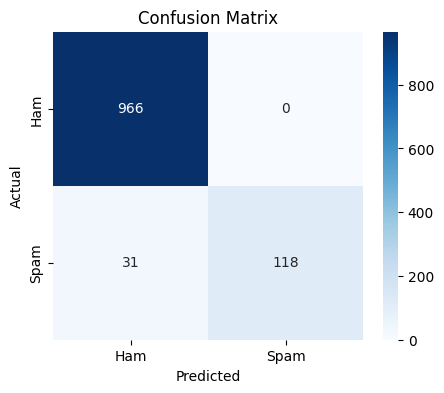

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [13]:
def predict_sms(text):
    processed = clean_text(text)
    vectorized = tfidf.transform([processed]).toarray()
    prediction = model.predict(vectorized)[0]
    probability = model.predict_proba(vectorized)[0]

    label = "SPAM" if prediction == 1 else "HAM"
    confidence = (
        probability[1] if prediction == 1 else probability[0]
    ) * 100

    print(f"Message: '{text}'")
    print(f"Result:  {label} ({confidence:.2f}% confidence)\n")


# Test examples
sample_1 = "Congratulations! You have won a $1,000 gift card. Call 08002988890 now to claim your prize."
sample_2 = "Hey, are we still meeting at the library at 5 PM today?"
sample_3 = "URGENT: Your account has been temporarily locked. Click here to verify your identity."

predict_sms(sample_1)
predict_sms(sample_2)
predict_sms(sample_3)

Message: 'Congratulations! You have won a $1,000 gift card. Call 08002988890 now to claim your prize.'
Result:  SPAM (93.56% confidence)

Message: 'Hey, are we still meeting at the library at 5 PM today?'
Result:  HAM (98.91% confidence)

Message: 'URGENT: Your account has been temporarily locked. Click here to verify your identity.'
Result:  SPAM (73.16% confidence)

